In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage, SystemMessage

from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 构建子图
class SubgraphState(MessagesState):
    system_prompt: SystemMessage

def llm_mode(state: SubgraphState) -> SubgraphState:
    system_prompt = state["system_prompt"]
    messages = state["messages"]
    response = model.invoke([system_prompt] + messages)
    return {
        "messages": [response]
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("llm_mode", llm_mode)
builder.add_edge(START, "llm_mode")
builder.add_edge("llm_mode", END)
subgraph = builder.compile(checkpointer=True)

# 构建父图
class ParentState(TypedDict):
    user_input: str
    assistant_response: str

def call_subgraph(state: ParentState) -> ParentState:
    user_input = state["user_input"]
    response = subgraph.invoke(
        {
            "system_prompt": SystemMessage("你是个善解人意的助手"),
            "messages": [HumanMessage(user_input)]
        }
    )
    assistant_response = response["messages"][-1].content
    return {
        "assistant_response": assistant_response
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)
config = {"configurable": {"thread_id": "subgraph_stream_test"}}

print("\n", "=" * 30, "-> 第一次运行结果 <-", "=" * 30)
# chunk 形如
# (('call_subgraph',), 'messages', (AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'deepseek'}, id='lc_run--019efd65-c54e-7012-912e-29ff4f84328e', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'thread_id': 'subgraph_stream_test', 'langgraph_step': 1, 'langgraph_node': 'llm_mode', 'langgraph_triggers': ('branch:to:llm_mode',), 'langgraph_path': ('__pregel_pull', 'llm_mode'), 'langgraph_checkpoint_ns': 'call_subgraph|llm_mode:55577c3e-22da-877a-c77b-f16bdbcd2c6c', 'checkpoint_ns': 'call_subgraph:9c469391-f094-1c1b-c5d7-6578f1603151', 'ls_provider': 'deepseek', 'ls_model_name': 'deepseek-v4-flash', 'ls_model_type': 'chat', 'ls_temperature': None}))

for chunk in parent_graph.stream(
    {
        "user_input": "花儿为什么这样红？"
    },
    config=config,
    subgraphs=True,   # 必须要有，否则不打印子图里面的内容
    stream_mode=["messages"]
):
    print(chunk[2][0].content, end="", flush=True)

print("\n", "=" * 30, "-> 第二次运行结果 <-", "=" * 30)
for chunk in parent_graph.stream(
    {
        "user_input": "刚才我们聊了什么？"
    },
    config=config,
    subgraphs=True,
    stream_mode=["messages"]
):
    print(chunk[2][0].content, end="", flush=True)


 ============================== -> 第一次运行结果 <- ==============================
你问的“花儿为什么这样红”既可以是一首歌，也可以是一个科学问题。我从两个角度简单说说：

**如果是指那首歌：** 《花儿为什么这样红》是电影《冰山上的来客》的插曲，由雷振邦改编自塔吉克族民歌。它借“红花”象征纯洁的爱情和边防战士的深情，旋律悠长，带着高原民歌的苍凉与热烈，所以“红”在这里是一种情感和文化的意象——红得动人，是因为它唱的是思念与忠贞。

**如果是指植物学上的“红”：** 花瓣呈现红色，主要靠花青素（anthocyanins）这类色素。花青素在不同酸碱度下会变色：偏酸时偏红，偏碱时偏蓝。花朵“红”通常是为了吸引传粉者——蜂蝶鸟类对红色敏感，红色花在绿叶背景里格外醒目，等于给昆虫发了个“这里有花蜜”的信号。另外，有些花红还和紫外线反射、温度保护有关。

所以，一朵花“红”既是化学和进化的结果，也可以被写成一首情歌。你更想聊哪一个方向？
 ============================== -> 第二次运行结果 <- ==============================
我们刚才聊了“花儿为什么这样红”这个说法。我把它拆成两个角度来回答：

1. **歌曲角度**：《花儿为什么这样红》是电影《冰山上的来客》的插曲，改编自塔吉克族民歌，借红花象征纯洁爱情和边防战士的深情。
2. **植物学角度**：花瓣发红主要靠花青素，色素随酸碱度变化会呈现不同颜色；红色通常是为了吸引传粉者。

最后我问你更想聊哪个方向。需要我继续展开哪一个吗？

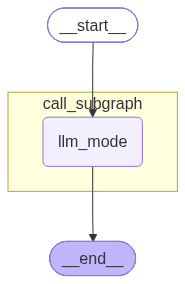

In [3]:
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)